# Exercise 3: Exploring hyper-parameters

In this exercise you train a small neural network to recognise **environmental sounds**: a dog barking, rain, a crying baby, a chainsaw, and 46 other classes. The network is simple. The main work is to **explore its hyper-parameters**: you train many models, read plots of their losses, decide which settings work best, and finally commit to your own best configuration.

The audio clips are turned into **log-mel spectrograms**, small images of how the energy at each frequency changes over time. One model then trains in a few seconds on a laptop CPU, so you can afford to train dozens of them.

**Tasks**

1. Log-mel features (2 points)
2. The network (4 points)
3. The training and evaluation loops (4 points)
4. One sweep function for every hyper-parameter (4 points)
5. Exploration sessions: learning rate, batch size, number of blocks and channels, kernel size, dropout and epochs (3 points)
6. Your final configuration (3 points)

For tasks 1–4, the visible tests give half of the points and hidden tests, run after submission, the other half.

**Deliverables:** submit the notebook `ex3.ipynb` and your final model `best_model.pth`, which the notebook saves in Task 6. Do not rename the notebook.

**Run time:** all training in this notebook takes about 10–15 minutes on a laptop CPU. In addition, the dataset (650 MB) is downloaded once and its features are computed once (about a minute). A GPU does not help here: the models are so small that a CPU is about as fast.

**Before you start:** install librosa, the audio library used for the features, if you do not have it: `pip install librosa`. Keep the file `ex3_helpers.py` next to the notebook. It holds the code that is not part of your tasks: downloading the dataset, the plots, and the code behind the tests. You do not need to read it.

**Note:** the variable `feedback_txt` is used for autograding. Do not modify or delete it. You may change `skip_training` in the cell where it is defined, but nowhere else. Set it to `True` to run the tests without training.

In [ ]:
skip_training = False   # set to True to run the tests without training any model

In [ ]:
# Do not delete this cell

In [ ]:
# Do not delete this cell

### Libraries

In [ ]:
import os
import copy
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import librosa

try:
    from ex3_helpers import (get_esc50, make_datasets, show_examples, plot_history, plot_sweep, run_sweep, report_run,
                             plot_journey, plot_per_class, checked_config)
except ImportError as e:
    raise ImportError("ex3_helpers.py was not found. Put it in the same folder as this notebook.") from e

import warnings
warnings.filterwarnings("ignore")

feedback_txt = []   # preserved for autograding purposes only. Do not modify or delete it.

In [ ]:
# Helpers for grading. Do not modify or delete this cell.
import shutil
import tempfile

# True while the autograder runs this notebook
AUTOGRADING = os.environ.get('NBGRADER_EXECUTION') == 'autograde' or globals().get('autograding', False)

# The graded model. During grading it is copied before any of your code runs, so nothing can overwrite it.
SUBMITTED_MODEL = 'best_model.pth'
if AUTOGRADING and os.path.exists(SUBMITTED_MODEL):
    SUBMITTED_MODEL = shutil.copy(SUBMITTED_MODEL, tempfile.mkdtemp())

tests_passed, tests_failed = [], []    # for the feedback


def record_test_pass(name):
    tests_passed.append(name)


def record_test_failure(name, error):
    # Add a line about a failed test to feedback_txt
    tests_failed.append(name)
    if isinstance(error, AssertionError):
        message = str(error)
    elif isinstance(error, NotImplementedError):
        message = "the code is not implemented yet (raise NotImplementedError() is still there)."
    elif isinstance(error, Exception):
        message = f"your code raised {type(error).__name__}" + (f": {error}" if str(error) else ".")
    else:    # e.g. the cell was stopped because it ran too long
        message = f"the test was stopped ({type(error).__name__}), probably because it ran too long."
    feedback_txt.append(f"{name}: {message}")

### Device

The models in this exercise are small, so the CPU is about as fast as a GPU, and results on the CPU are exactly reproducible. You may change the device if you want.

In [ ]:
device = torch.device('cpu')

## The dataset: ESC-50

[ESC-50](https://github.com/karolpiczak/ESC-50) is a collection of 2000 environmental sound clips of 5 seconds, 40 clips for each of 50 classes: animals, natural sounds such as rain and wind, human sounds such as coughing and snoring, domestic sounds, and urban sounds such as sirens and engines.

The clips come in 5 folds, and clips cut from the same original recording are always in the same fold. We use:

| folds | clips | used for |
|---|---|---|
| 1, 2, 3 | 1200 | training |
| 4 | 400 | **validation**: comparing hyper-parameters |
| 5 | 400 | **test**: looked at only once, at the very end |

The cell below downloads the dataset (about 650 MB) into `dataset_path` and unpacks it, unless it is already there. You can also download it yourself: on the GitHub page choose "Code → Download ZIP" and unpack it so that `dataset_path` contains the folder `ESC-50-master`.

*ESC-50 is published under the Creative Commons Attribution-NonCommercial license by K. J. Piczak: "ESC: Dataset for Environmental Sound Classification", Proceedings of the 23rd ACM International Conference on Multimedia, 2015.*

In [ ]:
dataset_path = './dataset_ex3'   # you can change the path if you want to store the dataset somewhere else

In [ ]:
# A TA sets the dataset folder for grading; otherwise dataset_path from the cell above is used
dataset_path = os.environ.get('EX3_DATASET_PATH') or globals().get('TA_dataset_path') or globals().get('dataset_path', './dataset_ex3')
clips, esc50_folder = get_esc50(dataset_path, download=not AUTOGRADING)    # the autograder never downloads the dataset

## Task 1: Log-mel features (2 points)

A clip of 5 s at 22 050 Hz has 110 250 samples. Feeding such a long waveform to a network is slow. A **mel spectrogram** summarises it the way our ears do:

1. The clip is cut into short overlapping frames: `n_fft = 1024` samples (46 ms) each, one frame every `hop_length = 512` samples.
2. The power spectrum of every frame is computed.
3. The power is summed in `n_mels = 64` frequency bands. The bands are narrow at low frequencies and wide at high frequencies, like human pitch perception (the *mel* scale).
4. The power is converted to decibels, a logarithm. Sound power spans many orders of magnitude, and the logarithm compresses it, again like our hearing.

**Your task:** implement `log_mel(waveform, sr)`. Use

- [`librosa.feature.melspectrogram`](https://librosa.org/doc/0.11.0/generated/librosa.feature.melspectrogram.html) with the sampling rate `sr`, `n_fft=1024`, `hop_length=512` and `n_mels=64`, and
- [`librosa.power_to_db`](https://librosa.org/doc/0.11.0/generated/librosa.power_to_db.html) with its default arguments.

The function returns an array of shape `(64, number of frames)`. For a 5 s clip at 22 050 Hz, that is `(64, 216)`. All later tasks use these features, and your final model is graded on features made with the official `log_mel`, so make sure yours passes its test before you go on.

In [ ]:
def log_mel(waveform, sr):
    '''
    The log-mel spectrogram of a waveform.

    Parameters:
        waveform: 1-D numpy array, the audio samples
        sr: the sampling rate in Hz
    Returns:
        numpy array of shape (64, number of frames), in decibels
    '''
    # YOUR CODE HERE
    raise NotImplementedError()

In [ ]:
# Visible test of log_mel(), with a synthetic signal: a rising tone plus a little noise
from ex3_helpers import check_log_mel, test_signal
try:
    check_log_mel(log_mel, test_signal(2, 22050), 22050)
except BaseException as error:
    record_test_failure("Log-mel features: visible test", error)
    raise
record_test_pass("Log-mel features: visible test")
print(f"\033[92m{'Good job! All visible tests passed!'}\033[0m")

In [ ]:
# This cell contains hidden tests that are run after submission

### Listen and look

Run the cell below to listen to a few clips and look at their log-mel spectrograms. Can you see the regular ticks of the clock, the harmonics of the rooster, and the broadband noise of the rain? Bright means loud.

In [ ]:
if clips:
    show_examples(clips, esc50_folder, log_mel)

### Features of all clips

The cell below computes the features of all 2000 clips with your `log_mel` and saves them in `dataset_path/esc50_logmel.npz`, so that this is done only once. It takes about a minute. If you change `log_mel` later, the features are computed again.

Two more steps make training fast and stable:

- Every 4 neighbouring frames are averaged. A clip becomes a 64 × 54 array: 64 mel bands and 54 time steps of 93 ms.
- Every mel band is standardised to mean 0 and standard deviation 1, with the mean and standard deviation of the training clips.

The result is `train_set`, `val_set` and `test_set`, PyTorch datasets of (features, class) pairs.

In [ ]:
try:
    train_set, val_set, test_set, train_eval_set, class_names = make_datasets(dataset_path, clips, esc50_folder, log_mel,
                                                                              autograding=AUTOGRADING)
except BaseException as e:
    if AUTOGRADING:
        feedback_txt.append(f"Loading the features file in {dataset_path} failed ({type(e).__name__}: {e}). Please contact your TA.")
    raise

## Task 2: The network (4 points)

`SoundNet` is a 1-D convolutional network. Its convolutions slide along **time**, and the 64 mel bands are the input channels:

```
input                                  (batch, 64 mel bands, 54 time steps)
block 1: Conv1d(64 → channels)   → BatchNorm1d → ReLU → MaxPool1d(2)    (batch, channels, 27)
block 2: Conv1d(channels → channels) → BatchNorm1d → ReLU → MaxPool1d(2)    (batch, channels, 13)
...      n_layers blocks in total
average over time (global average pooling)                     (batch, channels)
Dropout(dropout) → Linear(channels → 50)                       (batch, 50) class scores
```

Every convolution has `kernel_size` and `padding=kernel_size // 2`, so that it keeps the number of time steps for odd kernel sizes. Every block halves the number of time steps (54 → 27 → 13 → 6 → 3 → 1), so deeper blocks see longer stretches of sound. Averaging over time makes the network indifferent to *when* in the clip a sound occurs.

**How the network sees a clip.** The figure follows one clip, a rooster, through a small trained `SoundNet` (3 blocks, 32 channels, kernel size 5). In every image, time runs from left to right and each row is one channel.

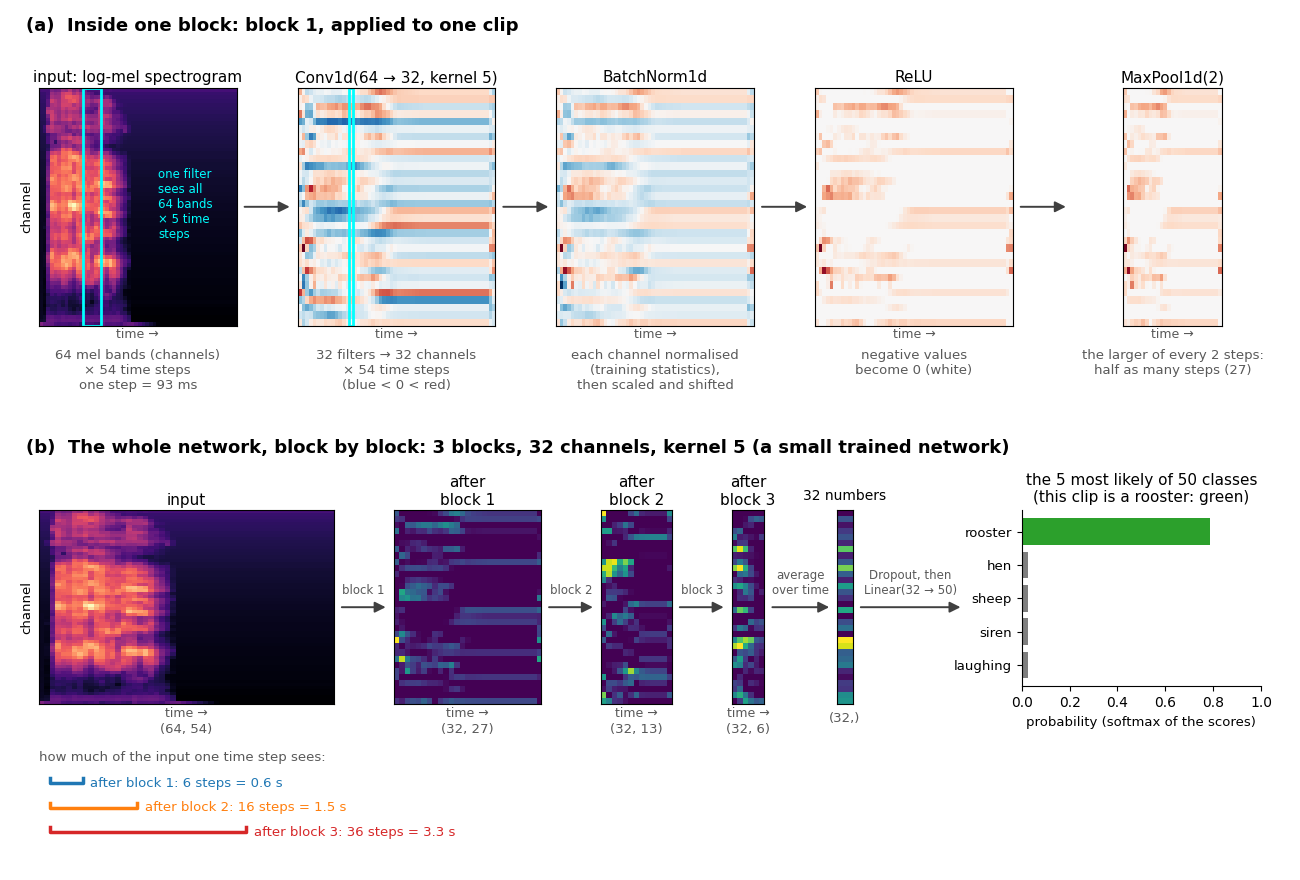

- **(a) Inside block 1.** Each of the 32 filters of the convolution looks at all 64 mel bands over 5 time steps at once (the cyan box) and slides along time; its outputs form one row of the next image. BatchNorm1d rescales every channel, ReLU sets the negative values to 0, and MaxPool1d keeps the larger of every two time steps.
- **(b) The whole network.** Every block halves the number of time steps, so one step of a deeper block summarises a longer stretch of sound: 0.6 s after block 1 and 3.3 s after block 3 (the coloured brackets). Averaging over time leaves one number per channel, and the linear layer turns these 32 numbers into a score for each of the 50 classes.

The network has four **structural hyper-parameters**: `n_layers` (1 to 5), `channels`, `kernel_size` and `dropout`.

**Your task:**
- In `__init__`, append the four layers of each block to the list `layers`, in the order above, with a loop over the blocks. The first block has `n_mels` input channels; the others have `channels`.
- In `forward`, pass the input through `self.blocks`, average over the time dimension, then apply `self.dropout` and `self.classifier`. Return the class scores without a softmax: `nn.CrossEntropyLoss` applies it.

With `n_layers=2, channels=64, kernel_size=3`, the network has 28 210 parameters.

Useful links: [Conv1d](https://pytorch.org/docs/stable/generated/torch.nn.Conv1d.html), [BatchNorm1d](https://pytorch.org/docs/stable/generated/torch.nn.BatchNorm1d.html), [MaxPool1d](https://pytorch.org/docs/stable/generated/torch.nn.MaxPool1d.html), [torch.mean](https://pytorch.org/docs/stable/generated/torch.mean.html)

In [ ]:
class SoundNet(nn.Module):
    def __init__(self, n_layers=2, channels=64, kernel_size=3, dropout=0.0, n_mels=64, n_classes=50):
        super().__init__()
        layers = []
        # YOUR CODE HERE
        raise NotImplementedError()
        self.blocks = nn.Sequential(*layers)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(channels, n_classes)

    def forward(self, x):
        '''
        x: features of shape (batch, n_mels, time steps)
        Returns the class scores (logits), shape (batch, n_classes)
        '''
        # YOUR CODE HERE
        raise NotImplementedError()

In [ ]:
# Visible test of SoundNet
from ex3_helpers import check_model
try:
    check_model(SoundNet, n_layers=2, channels=64, kernel_size=3, dropout=0.0)
    check_model(SoundNet, n_layers=1, channels=32, kernel_size=5, dropout=0.3)
except BaseException as error:
    record_test_failure("Network: visible test", error)
    raise
record_test_pass("Network: visible test")
print(f"\033[92m{'Good job! All visible tests passed!'}\033[0m")

In [ ]:
# This cell contains hidden tests that are run after submission

## Task 3: The training and evaluation loops (4 points)

**`train_one_epoch(model, loader, optimizer, loss_fn)`** trains the model for one pass over the training data:
- set the model to training mode;
- for every batch: move the inputs and targets to `device`, reset the gradients, compute the model's output and the loss, compute the gradients, and update the weights;
- return the average loss per sample over the epoch.

**`evaluate(model, loader, loss_fn)`** measures how well the model does, without changing it:
- set the model to evaluation mode, so that dropout is off and batch normalization uses its running statistics;
- turn off gradient tracking, which saves time and memory;
- for every batch: compute the output and the loss, and count the correct predictions (the class with the highest score);
- return the average loss per sample and the accuracy.

`loss_fn` returns the *mean* loss over a batch. To average over samples, add `loss.item() * batch_size` for every batch and divide by the number of samples at the end.

In [ ]:
def train_one_epoch(model, loader, optimizer, loss_fn):
    '''
    Train the model for one epoch. Returns the average training loss per sample.
    '''
    total_loss, n_samples = 0.0, 0
    # YOUR CODE HERE
    raise NotImplementedError()
    return total_loss / n_samples

In [ ]:
def evaluate(model, loader, loss_fn):
    '''
    Evaluate the model. Returns (average loss per sample, accuracy).
    '''
    total_loss, n_correct, n_samples = 0.0, 0, 0
    # YOUR CODE HERE
    raise NotImplementedError()
    return total_loss / n_samples, n_correct / n_samples

In [ ]:
# Visible test of train_one_epoch(), with a small stand-in model instead of SoundNet
from ex3_helpers import check_train_one_epoch
try:
    check_train_one_epoch(train_one_epoch, device)
except BaseException as error:
    record_test_failure("Training loop: visible test", error)
    raise
record_test_pass("Training loop: visible test")
print(f"\033[92m{'Good job! All visible tests passed!'}\033[0m")

In [ ]:
# This cell contains hidden tests that are run after submission

In [ ]:
# Visible test of evaluate(), with a small stand-in model instead of SoundNet
from ex3_helpers import check_evaluate
try:
    check_evaluate(evaluate, device)
except BaseException as error:
    record_test_failure("Evaluation loop: visible test", error)
    raise
record_test_pass("Evaluation loop: visible test")
print(f"\033[92m{'Good job! All visible tests passed!'}\033[0m")

In [ ]:
# This cell contains hidden tests that are run after submission

### Training a model from a configuration

A **configuration** is a dictionary with all eight hyper-parameters. The function `train_model(config, seed)` below builds a `SoundNet` from it, trains it with the Adam optimizer, using your `train_one_epoch` and `evaluate`, and returns the trained model and its **history**: a dictionary of lists with one value per epoch.

The learning rate is not constant: it starts at `config['lr']` and decays to zero along a cosine curve over the epochs ([CosineAnnealingLR](https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.CosineAnnealingLR.html)). This is common practice: large steps early on make fast progress, and small steps at the end let the model settle, so the final loss is stable rather than jumping from epoch to epoch.

| key | meaning |
|---|---|
| `'train_loss'` | loss on 400 training clips, measured with `evaluate` after the epoch |
| `'val_loss'` | loss on the validation clips |
| `'val_acc'` | accuracy on the validation clips |
| `'time'` | seconds since the start of training |

The training loss is measured the same way as the validation loss, in evaluation mode, so the two can be compared directly. Their difference, the **generalization gap**, shows how much the model over-fits the training clips.

The `seed` fixes the initial weights and the order of the batches. Training the same configuration with another seed gives a slightly different result: this is the *noise* that you have to keep in mind when you compare configurations.

In [ ]:
def train_model(config, seed=0, verbose=False):
    '''Train a SoundNet with the hyper-parameters in config. Returns the trained model and its history.'''
    if os.environ.get('NBGRADER_EXECUTION') == 'autograde':
        raise RuntimeError("No training during grading: the autograder grades the best_model.pth you submitted.")
    torch.manual_seed(seed)
    model = SoundNet(config['n_layers'], config['channels'], config['kernel_size'], config['dropout']).to(device)
    optimizer = optim.Adam(model.parameters(), lr=config['lr'], weight_decay=config['weight_decay'])
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=config['epochs'])
    loss_fn = nn.CrossEntropyLoss()
    train_loader = DataLoader(train_set, batch_size=config['batch_size'], shuffle=True,
                              generator=torch.Generator().manual_seed(seed))
    train_eval_loader = DataLoader(train_eval_set, batch_size=400)
    val_loader = DataLoader(val_set, batch_size=400)
    history = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'time': []}
    start = time.time()
    for epoch in range(1, config['epochs'] + 1):
        running_loss = train_one_epoch(model, train_loader, optimizer, loss_fn)
        scheduler.step()
        train_loss, _ = evaluate(model, train_eval_loader, loss_fn)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn)
        for key, value in zip(history, (train_loss, val_loss, val_acc, time.time() - start)):
            history[key].append(value)
        if verbose and (epoch % 5 == 0 or epoch == config['epochs']):
            print(f"epoch {epoch:3d}: train loss {train_loss:.3f}, validation loss {val_loss:.3f}, "
                  f"validation accuracy {val_acc:.3f}  ({time.time() - start:.0f} s)")
        if not np.isfinite(running_loss):
            print(f"The training diverged in epoch {epoch} (the loss is {running_loss}).")
            break
    report_run(config, seed, history)    # updates the live plot of run_sweep(), if one is running
    return model, history

### The starting point

This is the configuration you start from. It trains in a second or two. Its validation loss is poor: a model that guesses has a loss of ln 50 = 3.91. Run the cell and look at the curves. What do you think is wrong?

In [ ]:
base_config = {
    'n_layers': 1,          # number of convolutional blocks
    'channels': 32,         # channels of every convolution
    'kernel_size': 3,       # kernel size of every convolution
    'dropout': 0.0,         # dropout probability before the classifier
    'lr': 1e-4,             # learning rate of Adam
    'batch_size': 64,
    'weight_decay': 0.0,    # L2 penalty on the weights (Adam's weight_decay)
    'epochs': 20,
}
if AUTOGRADING or os.environ.get('NBGRADER_EXECUTION') == 'validate':
    skip_training = True    # the autograder never trains: it grades the best_model.pth you submit
if not skip_training:
    base_model, base_history = train_model(base_config, verbose=True)
    plot_history(base_history, 'Starting configuration')

## Task 4: One sweep function for every hyper-parameter (4 points)

To explore a hyper-parameter, you train the same configuration several times, changing only that hyper-parameter, and compare the final losses. To see how two hyper-parameters interact, you train every combination of their values. One function does both:

**`sweep(base_config, grid, seeds)`**
- `base_config`: the configuration to start from. Do not change it.
- `grid`: a dictionary from one or two hyper-parameter names to the lists of values to try.
- `seeds`: the seeds to train each configuration with. The results are averaged over them.

For every combination of values in `grid`: make a copy of `base_config`, set the values of the combination, and for every seed train a model with `train_model(config, seed=seed)`. From each history, take the **final** value, at the last epoch, of `'train_loss'`, `'val_loss'`, `'val_acc'` and `'time'`, and average it over the seeds. Also keep the history of the first seed, for plotting the learning curves.

The function returns a dictionary of numpy arrays with one entry per combination, already created for you in the template:

```python
results = sweep(base_config, {'lr': [1e-3, 1e-2]})
results['val_loss']        # shape (2,): the final validation loss with lr = 1e-3 and with lr = 1e-2
results['histories'][1]    # the history of the first seed with lr = 1e-2

results = sweep(base_config, {'n_layers': [1, 2, 3], 'channels': [32, 64]})
results['val_loss'][2, 0]  # n_layers = 3 and channels = 32
```

**Hints:** `np.ndindex(shape)` loops over all index tuples of an array: `(0,), (1,)` for shape `(2,)` and `(0, 0), (0, 1), (1, 0), ...` for shape `(3, 2)`. Use `copy.deepcopy(base_config)` for the copies.

*Why the final loss and not the lowest loss during training?* The model you keep is the one at the end of training. Stopping at the best epoch is a technique of its own (early stopping), and `epochs` is one of the hyper-parameters you will explore.

In [ ]:
def sweep(base_config, grid, seeds=(0,)):
    '''
    Train a model for every combination of the hyper-parameter values in grid.

    Parameters:
        base_config: dict with all hyper-parameters (not changed)
        grid: dict from one or two hyper-parameter names to lists of values
        seeds: the seeds; every combination is trained once per seed
    Returns:
        dict with numpy arrays of shape (len(values 1),) or (len(values 1), len(values 2)):
        'train_loss', 'val_loss', 'val_acc', 'time': the value at the last epoch, averaged over the seeds
        'histories': the history of the first seed
    '''
    names = list(grid)                                    # the names of the hyper-parameters in the grid
    shape = tuple(len(grid[name]) for name in names)      # e.g. (7,) or (4, 5)
    results = {key: np.zeros(shape) for key in ('train_loss', 'val_loss', 'val_acc', 'time')}
    results['histories'] = np.empty(shape, dtype=object)
    # YOUR CODE HERE
    raise NotImplementedError()
    return results

In [ ]:
# Visible test of sweep(). train_model() is replaced by a fake that returns a made-up history at once.
from ex3_helpers import check_sweep
try:
    check_sweep(sweep)
except BaseException as error:
    record_test_failure("Sweep: visible test", error)
    raise
record_test_pass("Sweep: visible test")
print(f"\033[92m{'Good job! All visible tests passed!'}\033[0m")

In [ ]:
# This cell contains hidden tests that are run after submission

## Task 5: Exploration sessions (3 points)

Now you decide. You keep your current best settings in **`my_config`**. Each session sweeps one or two hyper-parameters around `my_config` with `run_sweep(sweep, my_config, grid, title)`. It calls your `sweep`, shows its progress and a plot that grows after every training run, and at the end plots the results your `sweep` returned. You then **update `my_config` with the values you choose** and go on to the next session. This is how hyper-parameters are often tuned by hand: one or two at a time, keeping the best values found so far.

**How to read the plots**

- *One hyper-parameter:* on the left, the final training and validation loss for every value. The shaded area is the generalization gap; the star is the lowest validation loss. Below each value is the training time of one run. On the right, the validation loss during training for every value: it shows *why* a value wins or loses (too slow, unstable, over-fitting).
- *Two hyper-parameters:* on the left, the final validation loss of every combination (bright is better, the gold square is the best). On the right, the generalization gap (dark red means strong over-fitting).

**Do not just copy the star.** Runs with different seeds differ by about 0.05 in validation loss. If two values are within that noise of each other, the plot cannot tell which is better: prefer the cheaper or simpler one, or run the sweep with more seeds, e.g. `run_sweep(..., seeds=(0, 1))`.

Each session takes between a few seconds and a few minutes. When you train bigger models later, earlier choices may stop being the best ones; you can always go back and run a session again.

In [ ]:
my_config = copy.deepcopy(base_config)

### Session 1: Learning rate

The learning rate sets the size of the update steps, and it is usually the most important hyper-parameter. Its good values span several orders of magnitude, so it is swept on a logarithmic scale.

The best learning rate depends on the rest of the configuration. You will change the network a lot in the next sessions, so you will check the learning rate again in Session 6.

In [ ]:
grid_lr = {'lr': [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1]}
if not skip_training:
    results_lr = run_sweep(sweep, my_config, grid_lr, 'Session 1: learning rate')

Look at both panels. With the smallest learning rates, the curves on the right still go down steeply at the last epoch: the model has not finished learning. What happens at the largest learning rates?

**Choose a learning rate** and put it in `my_config`.

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()
print(my_config)

### Session 2: Batch size and learning rate

The batch size sets how many clips are used for each update step. With a fixed number of epochs, a smaller batch means **more** update steps, each based on fewer clips. The best learning rate depends on the batch size, so the two are swept together.

In [ ]:
grid_bs_lr = {'batch_size': [16, 32, 64, 128], 'lr': [3e-4, 1e-3, 3e-3, 1e-2]}
if not skip_training:
    results_bs_lr = run_sweep(sweep, my_config, grid_bs_lr, 'Session 2: batch size × learning rate')

**Question 1 (1 point).** Look at the column with the smallest learning rate (0.0003). Smaller batches give a clearly lower validation loss there than larger batches. What is the main reason?

- **a)** Small batches give less noisy gradients.
- **b)** With the same number of epochs, small batches make more update steps, and with small steps the model needs many of them.
- **c)** Small batches regularise the model, so it over-fits less.

Set `answer_1` to `'a'`, `'b'` or `'c'`. Then **choose a batch size and a learning rate** and put them in `my_config`. Keep in mind the training time under each heatmap row too.

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()
print(my_config)

In [ ]:
# Checks the format of answer_1 now; whether it is right is checked after submission
from ex3_helpers import check_answer_format
try:
    answer = check_answer_format(globals().get('answer_1'), 'answer_1')
except BaseException as error:
    record_test_failure("Question 1", error)
    raise
record_test_pass("Question 1")
print("Your answer is recorded.")

### Session 3: Number of blocks and channels

Now the structure of the network: the number of blocks `n_layers` and the number of `channels` in each. Together they set the network's **capacity**, how complicated a function it can learn. The right heatmap is important here: compare the gap of small and large networks.

In [ ]:
grid_structure = {'n_layers': [1, 2, 3, 4, 5], 'channels': [16, 32, 64, 128, 256]}
if not skip_training:
    results_structure = run_sweep(sweep, my_config, grid_structure, 'Session 3: blocks × channels')

**Question 2 (1 point).** Find the networks with 5 layers and many channels. Compared with the best network, they reach a *lower* training loss but a *higher* validation loss. What is happening?

- **a)** They under-fit: they are too small to learn the training clips.
- **b)** They over-fit: they learn the 1200 training clips so well, including details that do not generalise, that they do worse on new clips.
- **c)** Their training diverged because the learning rate is too high for them.

Set `answer_2`. Then **choose `n_layers` and `channels`** and put them in `my_config`.

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()
print(my_config)

In [ ]:
# Checks the format of answer_2 now; whether it is right is checked after submission
from ex3_helpers import check_answer_format
try:
    answer = check_answer_format(globals().get('answer_2'), 'answer_2')
except BaseException as error:
    record_test_failure("Question 2", error)
    raise
record_test_pass("Question 2")
print("Your answer is recorded.")

### Session 4: Kernel size

How many time steps does each convolution look at? Not every hyper-parameter matters equally. Compare the differences in this plot with the seed noise of about 0.05.

In [ ]:
grid_kernel = {'kernel_size': [1, 3, 5, 7, 9]}
if not skip_training:
    results_kernel = run_sweep(sweep, my_config, grid_kernel, 'Session 4: kernel size')

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()
print(my_config)

### Session 5: Dropout and training length

Your network is now big enough to over-fit. Dropout fights over-fitting: during training, it sets a random fraction `dropout` of the features before the classifier to zero, so the classifier cannot rely on any single feature. But it also makes learning slower. The number of epochs is a hyper-parameter as well, so the two are swept together.

This session takes a few minutes, because some runs are long. Because the learning rate decays over the whole training, a run of 80 epochs is not simply a longer run of 20 epochs: its schedule is stretched. So every value of `epochs` is trained from scratch.

In [ ]:
grid_regularization = {'dropout': [0.0, 0.2, 0.4, 0.6], 'epochs': [20, 40, 80]}
if not skip_training:
    results_regularization = run_sweep(sweep, my_config, grid_regularization, 'Session 5: dropout × epochs')

**Question 3 (1 point).** In the left heatmap, compare the column for the shortest training (20 epochs) with the column for the longest (80 epochs). Which statement matches your plot?

- **a)** Dropout helps most in short training, because it makes learning faster.
- **b)** Dropout helps most in long training: it slows learning down, but it prevents the over-fitting that long training causes.
- **c)** Dropout hurts in both, because it throws away information.

Set `answer_3`. Then **choose `dropout` and `epochs`** and put them in `my_config`.

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()
print(my_config)

In [ ]:
# Checks the format of answer_3 now; whether it is right is checked after submission
from ex3_helpers import check_answer_format
try:
    answer = check_answer_format(globals().get('answer_3'), 'answer_3')
except BaseException as error:
    record_test_failure("Question 3", error)
    raise
record_test_pass("Question 3")
print("Your answer is recorded.")

### Session 6: Learning rate, again

You chose the learning rate in Session 1 for a tiny network with one block of 32 channels. Your network is now much bigger, trains longer and uses dropout. Is that learning rate still the best one? This sweep uses two seeds, so that you can trust smaller differences.

In [ ]:
grid_lr_again = {'lr': [3e-4, 1e-3, 3e-3, 1e-2]}
if not skip_training:
    results_lr_again = run_sweep(sweep, my_config, grid_lr_again, 'Session 6: learning rate, again', seeds=(0, 1))

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()
print(my_config)

### Your own sweeps (optional)

Use this cell for any sweep you like before you commit. Does `weight_decay`, another way to fight over-fitting, help? Would 4 blocks work better now? Pass `seeds=(0, 1)` to `run_sweep` to check whether a difference is larger than the noise.

**You can explore as many hyper-parameters and combinations as you like.** The grid can hold three, four or more hyper-parameters, and every combination of their values is trained (your `sweep` handles any number of them if it loops with `np.ndindex`). A plot cannot show more than two hyper-parameters at once, so it then shows **slices** of the grid: one heatmap of the first two hyper-parameters for every combination of values of the others, all on the same colour scale. The number of runs is the product of the numbers of values (3 hyper-parameters with 4 values each make 64 runs), so watch the time left in the progress line.

If you do not need the plots, turn them off and collect the runs in a CSV file instead:

- `plot=False`: no plots, only the progress line and the best result.
- `csv_file='my_runs.csv'`: every run is added to this file as soon as it is done, with all its hyper-parameters, its seed and its final results. Nothing is lost if you stop the sweep, and you can analyse the file with pandas or a spreadsheet.

```python
grid_big = {'weight_decay': [0.0, 1e-4, 1e-3],
            'dropout': [0.2, 0.4],
            'n_layers': [3, 4]}                      # 3 x 2 x 2 = 12 runs
results_big = run_sweep(sweep, my_config, grid_big, 'Big sweep',
                        plot=False, csv_file='my_runs.csv')
```

The two options also work separately: `csv_file` with the plots on, or `plot=False` without a file.

In [ ]:
grid_own = {'weight_decay': [0.0, 1e-4, 1e-3, 1e-2]}
if not skip_training:
    results_own = run_sweep(sweep, my_config, grid_own, 'Own sweep')

## Task 6: Your final configuration (3 points)

Make your final choices in the cell below. Then run the training cell: it trains a model with `my_config` (seed 0) and saves it, together with `my_config`, in **`best_model.pth`**, which you submit.

Your saved model is graded by its **final validation loss**:

| final validation loss | points |
|---|---|
| at most 2.2 | 1 |
| at most 1.9 | 2 |
| at most 1.7 | 3 |

For comparison, the starting configuration has a validation loss of about 3.7, and fixing only its learning rate gives about 2.4. Your configuration must stay within these limits: `n_layers` 1–5, `channels` at most 256, `kernel_size` at most 9, `batch_size` at least 8, `epochs` at most 100.

You may notice that the final model does a little worse than the best run of your sessions. Picking the lowest of many noisy results favours runs that were lucky: the minimum of a sweep is an optimistic estimate.

In [ ]:
# Your final configuration
# YOUR CODE HERE
raise NotImplementedError()
print(my_config)

In [ ]:
if not skip_training:
    final_config = checked_config(my_config)    # plain numbers, within the limits
    final_model, final_history = train_model(final_config, verbose=True)
    torch.save({'config': final_config, 'state_dict': final_model.state_dict()}, 'best_model.pth')
    print("Your model and configuration are saved in best_model.pth.")
    plot_history(final_history, 'Your final model')

### Check your saved model

The three cells below load `best_model.pth`, the file you submit, and compute its final validation loss. If your `log_mel` passes its tests, they give the same result here as at grading. At grading, your model is evaluated on features made with the official `log_mel`, so with a wrong `log_mel` the loss there can be much worse. If a level fails, go back to the sessions, change `my_config`, and run the training cell again.

In [ ]:
# Level 1: final validation loss at most 2.2
from ex3_helpers import saved_model_val_loss


def check_level(threshold):
    assert 'val_set' in globals(), "The validation clips are not available because loading the features failed (see above)."
    loss, config = saved_model_val_loss(SUBMITTED_MODEL, SoundNet, val_set)
    print(f"Final validation loss of your saved model: {loss:.3f}  (configuration: {config})")
    if not AUTOGRADING and "Log-mel features: visible test" in tests_failed:
        print("Warning: your log_mel does not pass its test, so your features differ from the official ones. "
              "At grading, this model is evaluated on the official features, and its loss can be much worse.")
    assert loss <= threshold, (f"The final validation loss of your saved model is {loss:.3f}; this level needs at most {threshold}. "
                               "Go back to the sessions, improve my_config and run the training cell of Task 6 again.")


try:
    check_level(2.2)
except BaseException as error:
    record_test_failure("Final model, level 1 (validation loss at most 2.2)", error)
    raise
record_test_pass("Final model, level 1 (validation loss at most 2.2)")
print(f"\033[92m{'Level 1 passed!'}\033[0m")

In [ ]:
# Level 2: final validation loss at most 1.9
from ex3_helpers import saved_model_val_loss
try:
    check_level(1.9)
except BaseException as error:
    record_test_failure("Final model, level 2 (validation loss at most 1.9)", error)
    raise
record_test_pass("Final model, level 2 (validation loss at most 1.9)")
print(f"\033[92m{'Level 2 passed!'}\033[0m")

In [ ]:
# Level 3: final validation loss at most 1.7
from ex3_helpers import saved_model_val_loss
try:
    check_level(1.7)
except BaseException as error:
    record_test_failure("Final model, level 3 (validation loss at most 1.7)", error)
    raise
record_test_pass("Final model, level 3 (validation loss at most 1.7)")
print(f"\033[92m{'Level 3 passed! Well tuned.'}\033[0m")

### Your tuning journey, and the test set

You have used the validation clips for every decision, so the validation loss of your final model is a little optimistic. The test clips (fold 5) have not been used for anything yet. **Only now**, look at them, once. The plots show how far you came from the starting configuration, and which sounds your model recognises well or confuses.

In [ ]:
if not skip_training:
    test_loss, test_accuracy = evaluate(final_model, DataLoader(test_set, batch_size=400), nn.CrossEntropyLoss())
    print(f"Final model: validation loss {final_history['val_loss'][-1]:.3f}, accuracy {final_history['val_acc'][-1]:.3f}")
    print(f"             test loss       {test_loss:.3f}, accuracy {test_accuracy:.3f}")
    plot_journey(base_history, final_history, test_loss)
    plot_per_class(final_model, test_set, class_names, device)

### Think about it (not graded)

- Which hyper-parameters mattered most for this problem, and which hardly mattered?
- Which choices interacted, so that the best value of one depended on another?
- Is the test loss close to the validation loss of your final model? Why can it be higher?
- Look at the confused classes. Would you confuse them too, just by listening?

In [ ]:
# Do not delete this cell